In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../DATA/Obesity prediction.csv')

In [3]:
df.head()

,Gender,Age,Height,Weight,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          2111 non-null   object 
 1   Age             2111 non-null   float64
 2   Height          2111 non-null   float64
 3   Weight          2111 non-null   float64
 4   family_history  2111 non-null   object 
 5   FAVC            2111 non-null   object 
 6   FCVC            2111 non-null   float64
 7   NCP             2111 non-null   float64
 8   CAEC            2111 non-null   object 
 9   SMOKE           2111 non-null   object 
 10  CH2O            2111 non-null   float64
 11  SCC             2111 non-null   object 
 12  FAF             2111 non-null   float64
 13  TUE             2111 non-null   float64
 14  CALC            2111 non-null   object 
 15  MTRANS          2111 non-null   object 
 16  Obesity         2111 non-null   object 
dtypes: float64(8), object(9)
memory u

In [5]:
df['Obesity'].value_counts()

Obesity
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64

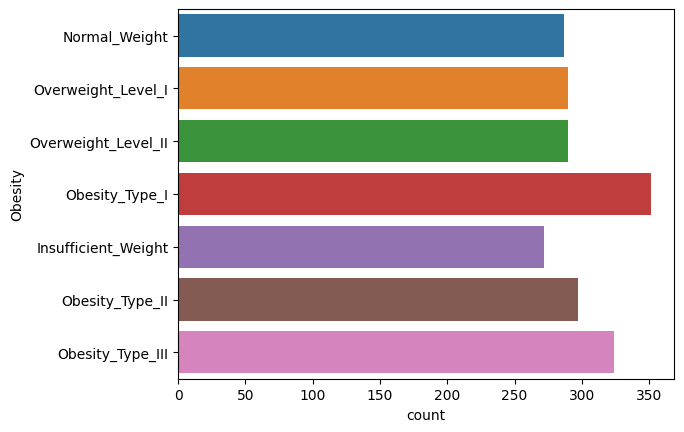

In [6]:
sns.countplot(y='Obesity', data=df, hue='Obesity');

In [7]:
df['Obesity'] = df['Obesity'].map({
    'Insufficient_Weight': 0, 
    'Normal_Weight': 1, 
    'Overweight_Level_I': 2, 
    'Overweight_Level_II': 3, 
    'Obesity_Type_I': 4, 
    'Obesity_Type_II': 5, 
    'Obesity_Type_III': 6
})

In [8]:
df = df.drop(['Weight', 'Height'], axis=1)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Gender          2111 non-null   object 
 1   Age             2111 non-null   float64
 2   family_history  2111 non-null   object 
 3   FAVC            2111 non-null   object 
 4   FCVC            2111 non-null   float64
 5   NCP             2111 non-null   float64
 6   CAEC            2111 non-null   object 
 7   SMOKE           2111 non-null   object 
 8   CH2O            2111 non-null   float64
 9   SCC             2111 non-null   object 
 10  FAF             2111 non-null   float64
 11  TUE             2111 non-null   float64
 12  CALC            2111 non-null   object 
 13  MTRANS          2111 non-null   object 
 14  Obesity         2111 non-null   int64  
dtypes: float64(6), int64(1), object(8)
memory usage: 247.5+ KB


In [10]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, auc
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.ensemble import IsolationForest

In [11]:
X = df.drop('Obesity', axis=1)

In [12]:
y = df['Obesity']

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=104, stratify=y)

In [14]:
num_features = X_train.select_dtypes(exclude='object').columns.tolist()
cat_features = X_train.select_dtypes(include='object').columns.tolist()

## Изоляционный Лес тут бесполезен так как удаляет настоящих людей и ухудшает работу модели

In [15]:
iso_forest = IsolationForest(contamination=0.01, random_state=104, n_jobs=-1, n_estimators=100)

In [16]:
mask = iso_forest.fit_predict(X_train[num_features])

In [17]:
X_train_cleaned = X_train[mask==1]
y_train_cleaned = y_train[mask==1]

In [18]:
X_train_cleaned.shape

(1671, 14)

In [19]:
X_train.shape

(1688, 14)

## Используем все данные без Изоляционного Леса

In [20]:
cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

In [21]:
num_transformer = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5)),
    ('scaler', StandardScaler())
])

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', cat_transformer, cat_features),
        ('num', num_transformer, num_features)
    ],
    remainder='passthrough'
)

In [23]:
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('model', LogisticRegressionCV(Cs=10,
                                   cv=10,
                                  penalty='l2',
                                  solver='lbfgs',
                                  max_iter=100_000,
                                  n_jobs=-1,
                                  random_state=104,
                                   class_weight='balanced'))
])

In [24]:
import warnings

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore')

In [25]:
%%time
pipe.fit(X_train, y_train)

CPU times: total: 1.02 s
Wall time: 13.1 s


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tran

In [26]:
y_pred = pipe.predict(X_test)
y_pred_proba = pipe.predict_proba(X_test)
y_train_proba = pipe.predict_proba(X_train)

In [27]:
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, average=None)
precision = precision_score(y_test, y_pred, average=None)

roc_auc_test = roc_auc_score(y_test, y_pred_proba, average=None, multi_class='ovr')
roc_auc_train = roc_auc_score(y_train, y_train_proba, average=None, multi_class='ovr')

In [28]:
best_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_model.C_}")

Лучшее значение C: [2.7825594 2.7825594 2.7825594 2.7825594 2.7825594 2.7825594 2.7825594]


In [29]:
accuracy

0.7801418439716312

In [30]:
recall

array([0.90740741, 0.55172414, 0.70689655, 0.68965517, 0.71428571,
       0.88333333, 1.        ])

In [31]:
precision

array([0.85964912, 0.66666667, 0.70689655, 0.6557377 , 0.71428571,
       0.85483871, 0.97014925])

In [32]:
roc_auc_test

array([0.98007628, 0.84388285, 0.9251299 , 0.87307511, 0.93116147,
       0.97112029, 1.        ])

In [33]:
roc_auc_train

array([0.99895775, 0.97987495, 0.97904628, 0.98306354, 0.98025885,
       0.99729272, 1.        ])

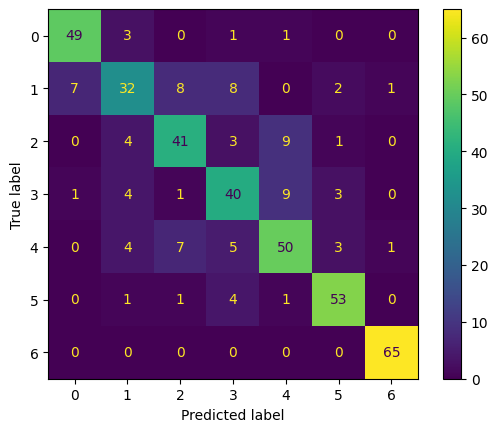

In [34]:
ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test);

In [35]:
def plot_multiclass_roc(clf, X_test, y_test, n_classes, figsize=(5,5)):
    y_score = clf.decision_function(X_test)

    # создаём пустые структуры
    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    # один раз вычисляем dummies 
    y_test_dummies = pd.get_dummies(y_test, drop_first=False).values
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_test_dummies[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    # roc для каждого класса
    fig, ax = plt.subplots(figsize=figsize)
    ax.plot([0, 1], [0, 1], 'k--')
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('Receiver operating characteristic example')
    for i in range(n_classes):
        ax.plot(fpr[i], tpr[i], label='ROC curve (area = %0.2f) for label %i' % (roc_auc[i], i))
    ax.legend(loc="best")
    ax.grid(alpha=.4)
    sns.despine()
    plt.show()

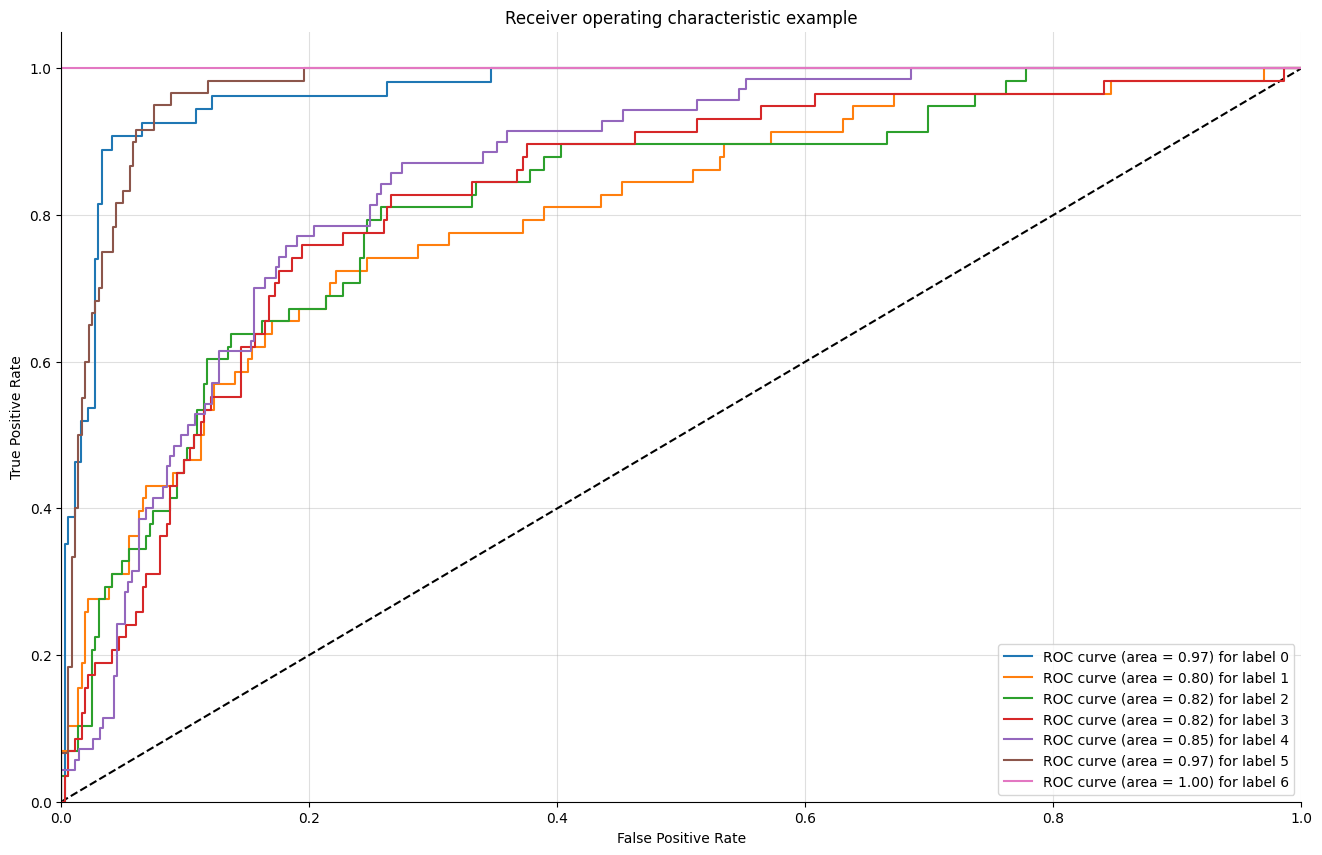

In [36]:
plot_multiclass_roc(pipe, X_test, y_test, n_classes=7, figsize=(16, 10))

In [37]:
pipe.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tran

In [38]:
y_pred_full = pipe.predict_proba(X)

In [39]:
best_final_model = pipe.named_steps['model']
print(f"Лучшее значение C: {best_final_model.C_}")
print(f"Лучшее значение l1_ratio: {best_final_model.l1_ratio_}")

Лучшее значение C: [2.7825594 2.7825594 2.7825594 2.7825594 2.7825594 2.7825594 2.7825594]
Лучшее значение l1_ratio: [None None None None None None None]


In [40]:
roc_auc_full = roc_auc_score(y, y_pred_full, average=None, multi_class='ovr')

In [41]:
roc_auc_full

array([0.99876052, 0.97712077, 0.97701907, 0.97574088, 0.97629015,
       0.99713601, 1.        ])

In [42]:
df['family_history'].unique()

array(['yes', 'no'], dtype=object)

In [43]:
df['FAVC'].unique()

array(['no', 'yes'], dtype=object)

In [44]:
df['CAEC'].unique()

array(['Sometimes', 'Frequently', 'Always', 'no'], dtype=object)

In [45]:
df['SMOKE'].unique()

array(['no', 'yes'], dtype=object)

In [46]:
df['SCC'].unique()

array(['no', 'yes'], dtype=object)

In [47]:
df['CALC'].unique()

array(['no', 'Sometimes', 'Frequently', 'Always'], dtype=object)

In [48]:
df['MTRANS'].unique()

array(['Public_Transportation', 'Walking', 'Automobile', 'Motorbike',
       'Bike'], dtype=object)

In [49]:
df[df['Obesity'] == 6].head()

,Gender,Age,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,Obesity
202,Female,26.000000,yes,yes,3.0,3.0,Sometimes,yes,1.000000,no,0.000000,1.0,Sometimes,Public_Transportation,6
344,Male,18.000000,yes,yes,3.0,3.0,Frequently,no,2.000000,no,2.000000,1.0,Sometimes,Public_Transportation,6
403,Female,26.000000,yes,no,3.0,3.0,Sometimes,no,3.000000,no,0.000000,0.0,no,Automobile,6
498,Female,25.196214,yes,yes,3.0,3.0,Sometimes,no,1.152736,no,0.319156,1.0,Sometimes,Public_Transportation,6
499,Female,18.503343,yes,yes,3.0,3.0,Sometimes,no,1.115967,no,1.541072,1.0,Sometimes,Public_Transportation,6


In [50]:
obesity_test_profiles = {
    'Gender': ['Female', 'Male', 'Female', 'Male', 'Male', 'Male', 'Female'],
    'Age': [18.0, 22.0, 20.0, 23.0, 27.0, 26.0, 24.0],
    'family_history': ['no', 'no', 'yes', 'no', 'yes', 'yes', 'yes'],
    'FAVC': ['no', 'no', 'yes', 'no', 'yes', 'yes', 'yes'],
    'FCVC': [3.0, 3.0, 2.0, 2.0, 3.0, 2.0, 3.0],
    'NCP': [3.0, 3.0, 3.0, 1.0, 3.0, 3.0, 3.0],
    'CAEC': ['no', 'Sometimes', 'Sometimes', 'Sometimes', 'Frequently', 'Sometimes', 'Sometimes'],
    'SMOKE': ['no', 'no', 'no', 'no', 'no', 'no', 'no'],
    'CH2O': [3.0, 2.5, 2.0, 2.0, 2.8, 2.0, 1.0],
    'SCC': ['yes', 'no', 'no', 'no', 'no', 'no', 'no'],
    'FAF': [3.0, 2.0, 1.0, 0.0, 2.0, 0.0, 0.0],
    'TUE': [0.0, 0.0, 1.0, 0.0, 2.0, 1.0, 0.0],
    'CALC': ['no', 'no', 'Sometimes', 'Sometimes', 'Sometimes', 'Sometimes', 'Sometimes'],
    'MTRANS': ['Walking', 'Walking', 'Public_Transportation', 'Public_Transportation', 'Public_Transportation', 'Automobile', 'Public_Transportation']
}

In [51]:
inference_df = pd.DataFrame(obesity_test_profiles)

In [52]:
inference_df

,Gender,Age,family_history,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,18.0,no,no,3.0,3.0,no,no,3.0,yes,3.0,0.0,no,Walking
1,Male,22.0,no,no,3.0,3.0,Sometimes,no,2.5,no,2.0,0.0,no,Walking
2,Female,20.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,1.0,1.0,Sometimes,Public_Transportation
3,Male,23.0,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation
4,Male,27.0,yes,yes,3.0,3.0,Frequently,no,2.8,no,2.0,2.0,Sometimes,Public_Transportation
5,Male,26.0,yes,yes,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,Sometimes,Automobile
6,Female,24.0,yes,yes,3.0,3.0,Sometimes,no,1.0,no,0.0,0.0,Sometimes,Public_Transportation


In [53]:
preds = pipe.predict(inference_df)
probs = pipe.predict_proba(inference_df)

In [54]:
class_names = {
    0: 'Insufficient_Weight (Дефицит массы)',
    1: 'Normal_Weight (Идеальная норма)',
    2: 'Overweight_Level_I (Избыточный вес 1-й ст.)',
    3: 'Overweight_Level_II (Избыточный вес 2-й ст.)',
    4: 'Obesity_Type_I (Ожирение 1-й степени)',
    5: 'Obesity_Type_II (Ожирение 2-й степени)',
    6: 'Obesity_Type_III (Ожирение 3-й степени)'
}

print("="*80)
print("🦾 ВЕРДИКТ МУЛЬТИКЛАССОВОЙ МЕДИЦИНСКОЙ МОДЕЛИ:")
print("="*80)

for idx in range(7):
    predicted_class = preds[idx]
    max_prob = np.max(probs[idx]) * 100
    
    print(f"Человек №{idx+1} (Ожидался класс {class_names[idx]}):")
    print(f"  -> Вердикт модели: {class_names[predicted_class]}")
    print(f"  -> Уверенность модели: {max_prob:.2f}%")
    print("-" * 80)

🦾 ВЕРДИКТ МУЛЬТИКЛАССОВОЙ МЕДИЦИНСКОЙ МОДЕЛИ:
Человек №1 (Ожидался класс Insufficient_Weight (Дефицит массы)):
  -> Вердикт модели: Insufficient_Weight (Дефицит массы)
  -> Уверенность модели: 99.76%
--------------------------------------------------------------------------------
Человек №2 (Ожидался класс Normal_Weight (Идеальная норма)):
  -> Вердикт модели: Normal_Weight (Идеальная норма)
  -> Уверенность модели: 94.40%
--------------------------------------------------------------------------------
Человек №3 (Ожидался класс Overweight_Level_I (Избыточный вес 1-й ст.)):
  -> Вердикт модели: Overweight_Level_I (Избыточный вес 1-й ст.)
  -> Уверенность модели: 55.84%
--------------------------------------------------------------------------------
Человек №4 (Ожидался класс Overweight_Level_II (Избыточный вес 2-й ст.)):
  -> Вердикт модели: Overweight_Level_II (Избыточный вес 2-й ст.)
  -> Уверенность модели: 97.77%
---------------------------------------------------------------------

In [55]:
class_percents = df['Obesity'].value_counts(normalize=True) * 100

baseline_string = f"0: {class_percents[0]:.1f}%, 1: {class_percents[1]:.1f}%, 2: {class_percents[2]:.1f}%, 3: {class_percents[3]:.1f}%, 4: {class_percents[4]:.1f}%, 5: {class_percents[5]:.1f}%, 6: {class_percents[6]:.1f}%"
print(f"{baseline_string}")

0: 12.9%, 1: 13.6%, 2: 13.7%, 3: 13.7%, 4: 16.6%, 5: 14.1%, 6: 15.3%


In [56]:
import json
import os

advanced_report = {
    "project": "Obesity Prediction",
    "model": "LogisticRegressionCV",
    "trained_date": '2026-07',
    "test_parameters": {
        "cv": best_model.cv,
        "penalty": best_model.penalty,
        "solver":best_model.solver,
        "C": best_model.C_.tolist()[0],
    },
    "final_parameters": {
        "cv": best_final_model.cv,
        "penalty": best_final_model.penalty,
        "solver":best_final_model.solver,
        "C": best_final_model.C_.tolist()[0],
    },
    "metrics": {
        "Accuracy Score": accuracy,
        "Precision Score": {
            "Insufficient_Weight": precision[0],
            "Normal_Weight": precision[1],
            "Overweight_Level_I": precision[2],
            "Overweight_Level_II": precision[3],
            "Obesity_Type_I": precision[4],
            "Obesity_Type_II": precision[5],
            "Obesity_Type_III": precision[6]
        },
        "Recall Score": {
            "Insufficient_Weight": recall[0],
            "Normal_Weight": recall[1],
            "Overweight_Level_I": recall[2],
            "Overweight_Level_II": recall[3],
            "Obesity_Type_I": recall[4],
            "Obesity_Type_II": recall[5],
            "Obesity_Type_III": recall[6]
        },
        "ROC AUC Score Train": {
            "Insufficient_Weight": roc_auc_train[0],
            "Normal_Weight": roc_auc_train[1],
            "Overweight_Level_I": roc_auc_train[2],
            "Overweight_Level_II": roc_auc_train[3],
            "Obesity_Type_I": roc_auc_train[4],
            "Obesity_Type_II": roc_auc_train[5],
            "Obesity_Type_III": roc_auc_train[6]
        },
        "ROC AUC Score Test": {
            "Insufficient_Weight": roc_auc_test[0],
            "Normal_Weight": roc_auc_test[1],
            "Overweight_Level_I": roc_auc_test[2],
            "Overweight_Level_II": roc_auc_test[3],
            "Obesity_Type_I": roc_auc_test[4],
            "Obesity_Type_II": roc_auc_test[5],
            "Obesity_Type_III": roc_auc_test[6]
        },
        "ROC AUC Score Full": {
            "Insufficient_Weight": roc_auc_full[0],
            "Normal_Weight": roc_auc_full[1],
            "Overweight_Level_I": roc_auc_full[2],
            "Overweight_Level_II": roc_auc_full[3],
            "Obesity_Type_I": roc_auc_full[4],
            "Obesity_Type_II": roc_auc_full[5],
            "Obesity_Type_III": roc_auc_full[6]
        },
        "Class Balance": baseline_string
    }
}


filename = "model_description.json"

with open(filename, "w", encoding="utf-8") as f:
    json.dump(advanced_report, f, indent=4, ensure_ascii=False)

In [57]:
from joblib import dump, load

In [58]:
dump(pipe, "model/obesity_prediction_logistic_regression_cv_2026_v1.pkl")

['model/obesity_prediction_logistic_regression_cv_2026_v1.pkl']

In [59]:
loaded_pipe = load("model/obesity_prediction_logistic_regression_cv_2026_v1.pkl")

In [60]:
preds = loaded_pipe.predict(inference_df)
probs = loaded_pipe.predict_proba(inference_df)

In [61]:
class_names = {
    0: 'Insufficient_Weight (Дефицит массы)',
    1: 'Normal_Weight (Идеальная норма)',
    2: 'Overweight_Level_I (Избыточный вес 1-й ст.)',
    3: 'Overweight_Level_II (Избыточный вес 2-й ст.)',
    4: 'Obesity_Type_I (Ожирение 1-й степени)',
    5: 'Obesity_Type_II (Ожирение 2-й степени)',
    6: 'Obesity_Type_III (Ожирение 3-й степени)'
}

print("="*80)
print("🦾 ВЕРДИКТ МУЛЬТИКЛАССОВОЙ МЕДИЦИНСКОЙ МОДЕЛИ:")
print("="*80)

for idx in range(7):
    predicted_class = preds[idx]
    max_prob = np.max(probs[idx]) * 100
    
    print(f"Человек №{idx+1} (Ожидался класс {class_names[idx]}):")
    print(f"  -> Вердикт модели: {class_names[predicted_class]}")
    print(f"  -> Уверенность модели: {max_prob:.2f}%")
    print("-" * 80)

🦾 ВЕРДИКТ МУЛЬТИКЛАССОВОЙ МЕДИЦИНСКОЙ МОДЕЛИ:
Человек №1 (Ожидался класс Insufficient_Weight (Дефицит массы)):
  -> Вердикт модели: Insufficient_Weight (Дефицит массы)
  -> Уверенность модели: 99.76%
--------------------------------------------------------------------------------
Человек №2 (Ожидался класс Normal_Weight (Идеальная норма)):
  -> Вердикт модели: Normal_Weight (Идеальная норма)
  -> Уверенность модели: 94.40%
--------------------------------------------------------------------------------
Человек №3 (Ожидался класс Overweight_Level_I (Избыточный вес 1-й ст.)):
  -> Вердикт модели: Overweight_Level_I (Избыточный вес 1-й ст.)
  -> Уверенность модели: 55.84%
--------------------------------------------------------------------------------
Человек №4 (Ожидался класс Overweight_Level_II (Избыточный вес 2-й ст.)):
  -> Вердикт модели: Overweight_Level_II (Избыточный вес 2-й ст.)
  -> Уверенность модели: 97.77%
---------------------------------------------------------------------